In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
df = pd.read_csv("student-mat.csv", sep=";")

print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (395, 33)

Columns:
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 

In [ ]:
df["Performance"] = (df["G3"] >= 10).astype(int)

print(df[["G3", "Performance"]].head(10))

print("\nPerformance Counts:")
print(df["Performance"].value_counts())

   G3  Performance
0   6            0
1   6            0
2  10            1
3  15            1
4  10            1
5  15            1
6  11            1
7   6            0
8  19            1
9  15            1

Performance Counts:
Performance
1    265
0    130
Name: count, dtype: int64


In [ ]:
X = df.drop(["G3", "Performance"], axis=1)

y = df["Performance"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.head())

Input features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Target values:
0    0
1    0
2    1
3    1
4    1
Name: Performance, dtype: int64


In [ ]:
X = pd.get_dummies(X, drop_first=True)

print("Number of features after encoding:", X.shape[1])

print("\nEncoded data:")
print(X.head())

Number of features after encoding: 41

Encoded data:
   age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
0   18     4     4           2          2         0       4         3      4   
1   17     1     1           1          2         0       5         3      3   
2   15     1     1           1          2         3       4         3      2   
3   15     4     2           1          3         0       3         2      2   
4   16     3     3           1          2         0       4         3      2   

   Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
0     1  ...             True           False           True       False   
1     1  ...            False           False          False        True   
2     2  ...             True           False           True       False   
3     1  ...             True           False          False        True   
4     1  ...            False           False          False        True   

   paid_y

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (316, 41)
Testing data: (79, 41)


In [ ]:
model = LogisticRegression(max_iter=2000)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred)

print("\nActual values:")
print(y_test.values)

Predicted values:
[1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 1 0 0 0 0 1 1 0 1 1 1 1 1 0 0 1 0 0 1 1 0 0
 0 1 0 0 0 1 1 1 0 1 1 1 1 0 1 1 0 0 0 0 1 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 0
 1 1 0 1 1]

Actual values:
[1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 1 0 0 0 0 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0
 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 1 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0
 1 1 0 1 1]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.8860759493670886
Accuracy Percentage: 88.60759493670885 %


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[24  2]
 [ 7 46]]


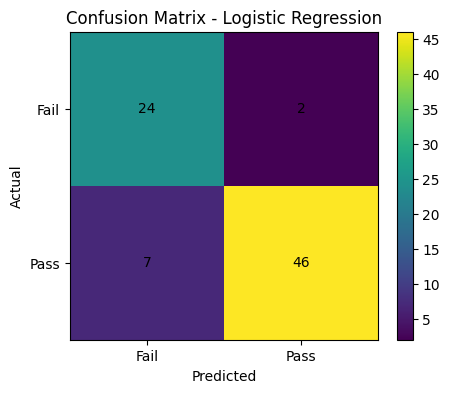

In [ ]:
plt.figure(figsize=(5, 4))

plt.imshow(cm)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Fail", "Pass"])
plt.yticks([0, 1], ["Fail", "Pass"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()

plt.show()

In [ ]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Fail", "Pass"]
))

Classification Report:
              precision    recall  f1-score   support

        Fail       0.77      0.92      0.84        26
        Pass       0.96      0.87      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.90      0.88        79
weighted avg       0.90      0.89      0.89        79



In [ ]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Fail", "Pass"]
))

Classification Report:
              precision    recall  f1-score   support

        Fail       0.77      0.92      0.84        26
        Pass       0.96      0.87      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.90      0.88        79
weighted avg       0.90      0.89      0.89        79



In [ ]:
print("Features used by the model:")

print(X.columns.tolist())

Features used by the model:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'school_MS', 'sex_M', 'address_U', 'famsize_LE3', 'Pstatus_T', 'Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher', 'Fjob_health', 'Fjob_other', 'Fjob_services', 'Fjob_teacher', 'reason_home', 'reason_other', 'reason_reputation', 'guardian_mother', 'guardian_other', 'schoolsup_yes', 'famsup_yes', 'paid_yes', 'activities_yes', 'nursery_yes', 'higher_yes', 'internet_yes', 'romantic_yes']


In [ ]:
new_student = pd.DataFrame({
    "school": ["GP"],
    "sex": ["F"],
    "age": [17],
    "address": ["U"],
    "famsize": ["GT3"],
    "Pstatus": ["T"],
    "Medu": [4],
    "Fedu": [4],
    "Mjob": ["teacher"],
    "Fjob": ["services"],
    "reason": ["course"],
    "guardian": ["mother"],
    "traveltime": [1],
    "studytime": [3],
    "failures": [0],
    "schoolsup": ["no"],
    "famsup": ["yes"],
    "paid": ["no"],
    "activities": ["yes"],
    "nursery": ["yes"],
    "higher": ["yes"],
    "internet": ["yes"],
    "romantic": ["no"],
    "famrel": [4],
    "freetime": [3],
    "goout": [3],
    "Dalc": [1],
    "Walc": [1],
    "health": [5],
    "absences": [2],
    "G1": [15],
    "G2": [14]
})

print(new_student)

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   17       U     GT3       T     4     4  teacher  services  ...   

  romantic famrel  freetime  goout  Dalc Walc health absences  G1  G2  
0       no      4         3      3     1    1      5        2  15  14  

[1 rows x 32 columns]


In [ ]:
new_student_encoded = pd.get_dummies(
    new_student,
    drop_first=True
)

new_student_encoded = new_student_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

print(new_student_encoded)

   age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
0   17     4     4           1          3         0       4         3      3   

   Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
0     1  ...                0               0              0           0   

   paid_yes  activities_yes  nursery_yes  higher_yes  internet_yes  \
0         0               0            0           0             0   

   romantic_yes  
0             0  

[1 rows x 41 columns]


In [ ]:
prediction = model.predict(new_student_encoded)

if prediction[0] == 0:
    print("Prediction: FAIL")
else:
    print("Prediction: PASS")

Prediction: PASS


In [ ]:
probability = model.predict_proba(new_student_encoded)

print("Probability of FAIL:", probability[0][0])
print("Probability of PASS:", probability[0][1])

Probability of FAIL: 3.505507739420821e-06
Probability of PASS: 0.9999964944922606


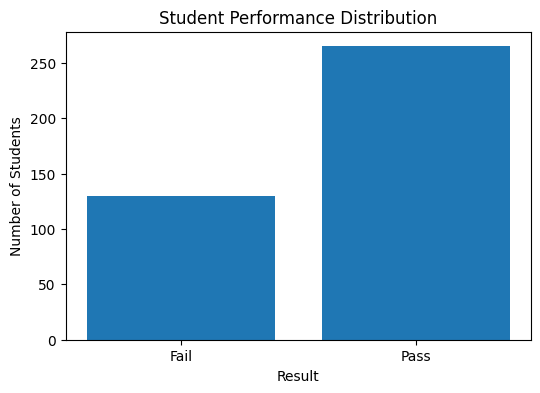

In [ ]:
performance_counts = df["Performance"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Fail", "Pass"],
    performance_counts.values
)

plt.title("Student Performance Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Students")

plt.show()